# Sales Prediction Using Python
**Author:** Syed Aon Muhammad Kazmi  
**Track:** Data Science | OASIS INFOBYTE

## Objective and data
Data: classic Advertising dataset, https://www.statlearning.com/s/Advertising.csv. Advertising spends are commonly reported in thousands of dollars and sales in thousands of units. Associations in this dataset do not establish causal advertising returns.

Reproducible seed: 42. Model selection uses cross-validation on training data; the held-out test set is evaluated once per candidate for reporting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
sns.set_theme(style='whitegrid', palette='colorblind')
SEED = 42
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
def save(name):
    plt.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
def inspect(df):
    print('Shape:', df.shape)
    display(df.head(), df.dtypes.to_frame('dtype'), df.isna().sum().to_frame('missing'), df.describe(include='all'))


Shape: (200, 4)
Duplicates: 0


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


,dtype
TV,float64
radio,float64
newspaper,float64
sales,float64


,missing
TV,0
radio,0
newspaper,0
sales,0


,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


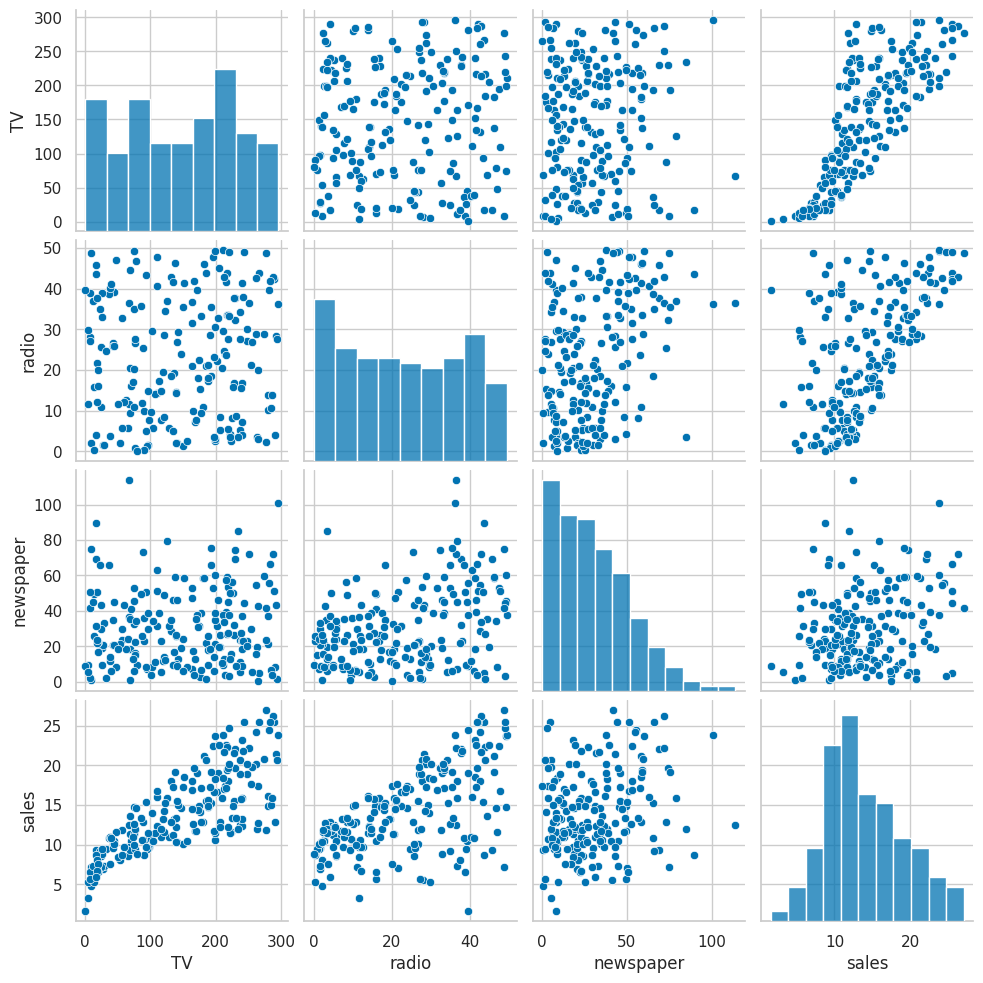

In [2]:
df=pd.read_csv('data/sales.csv');df=df.loc[:,~df.columns.str.startswith('Unnamed')];inspect(df)
assert df.columns.tolist()==['TV','radio','newspaper','sales']
print('Duplicates:',df.duplicated().sum());df=df.drop_duplicates().dropna(subset=['sales'])
sns.pairplot(df,diag_kind='hist');save('pairplot')

## Advertising spend and sales
The scatterplots show associations, including possible curvature and variation in sales at similar spending levels. A weak marginal association does not prove a channel is ineffective.

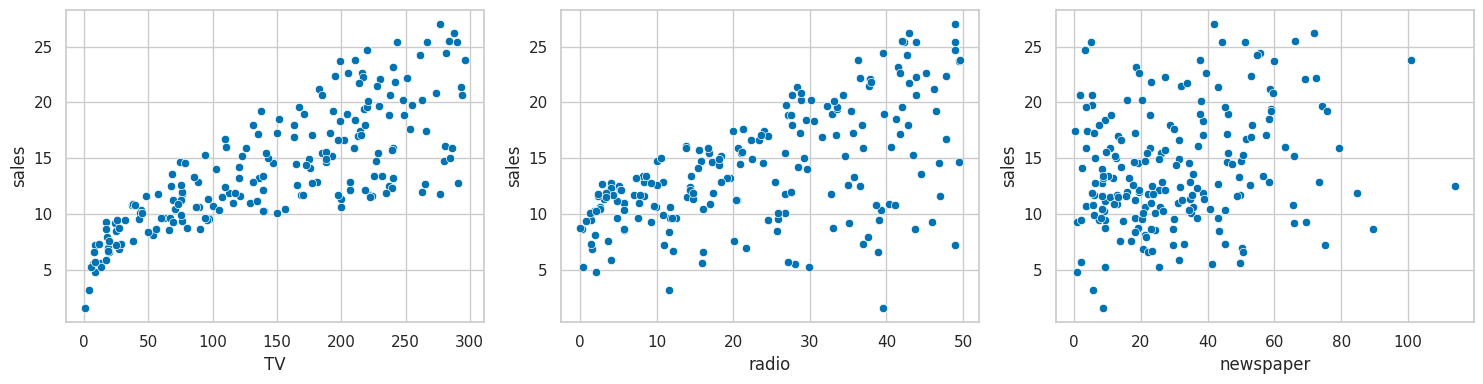

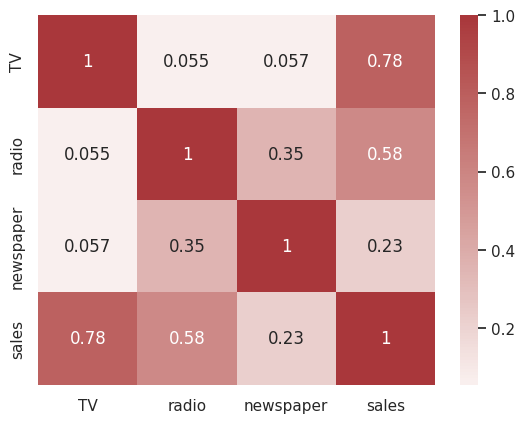

In [3]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes,['TV','radio','newspaper']):sns.scatterplot(data=df,x=col,y='sales',ax=ax)
plt.tight_layout();save('sales_scatterplots')
sns.heatmap(df.corr(),annot=True,cmap='vlag',center=0);save('correlation')

Selected: Polynomial degree 2 by lowest training CV RMSE.
Mean held-out residual: 0.0168


,Model,CV RMSE,MAE,RMSE,R2
1,Polynomial degree 2,0.675898,0.526179,0.642581,0.986918
0,Linear Regression,1.675810,1.460757,1.781600,0.899438


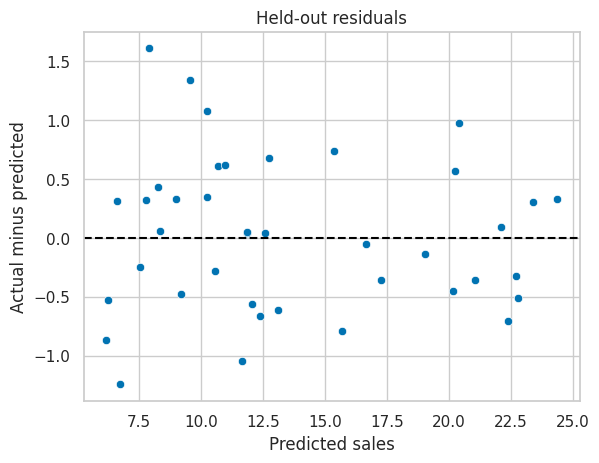

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
X_train,X_test,y_train,y_test=train_test_split(df[['TV','radio','newspaper']],df.sales,test_size=.2,random_state=SEED)
models={'Linear Regression':make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LinearRegression()),'Polynomial degree 2':make_pipeline(SimpleImputer(strategy='median'),PolynomialFeatures(degree=2,include_bias=False),StandardScaler(),LinearRegression())}
rows=[];cv=KFold(5,shuffle=True,random_state=SEED)
for name,model in models.items():
    score=-cross_val_score(model,X_train,y_train,cv=cv,scoring='neg_root_mean_squared_error').mean()
    model.fit(X_train,y_train);pred=model.predict(X_test)
    rows.append({'Model':name,'CV RMSE':score,'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'R2':r2_score(y_test,pred)})
results=pd.DataFrame(rows).sort_values('CV RMSE');display(results);results.to_csv(OUT/'metrics.csv',index=False)
best_name=results.iloc[0]['Model'];best=models[best_name];print('Selected:',best_name,'by lowest training CV RMSE.')
pred=best.predict(X_test);residual=y_test-pred
sns.scatterplot(x=pred,y=residual);plt.axhline(0,color='black',linestyle='--');plt.xlabel('Predicted sales');plt.ylabel('Actual minus predicted');plt.title('Held-out residuals');save('residuals')
print('Mean held-out residual:',round(residual.mean(),4))

## Channel interpretation
Standardised baseline coefficients compare associations per one standard deviation of spend, conditional on other channels. For the selected model, training permutation importance estimates the increase in MAE when a channel is shuffled. Neither is a causal estimate. Polynomial interactions mean that a channel’s effect can depend on the other spending levels.

Largest predictive importance: TV
Example prediction: 17.254435784211484


,Standardised coefficient
TV,3.764196
radio,2.792307
newspaper,0.055976


,Training MAE increase
TV,3.766272
radio,2.921124
newspaper,0.016591


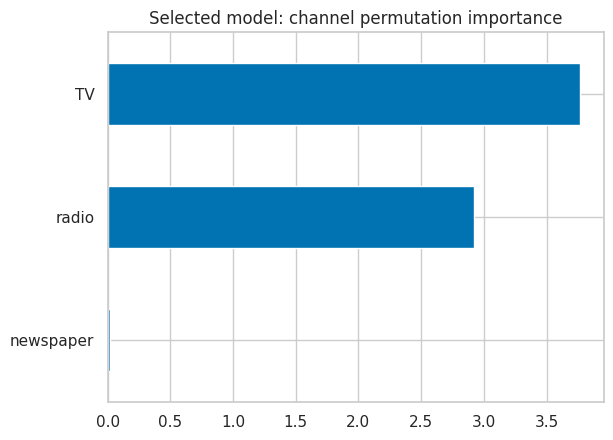

In [5]:
coeff=pd.Series(models['Linear Regression'].named_steps['linearregression'].coef_,index=X_train.columns);display(coeff.to_frame('Standardised coefficient'))
from sklearn.inspection import permutation_importance
imp=permutation_importance(best,X_train,y_train,n_repeats=10,random_state=SEED,scoring='neg_mean_absolute_error')
importance=pd.Series(imp.importances_mean,index=X_train.columns).sort_values(ascending=False);display(importance.to_frame('Training MAE increase'))
importance.sort_values().plot.barh(title='Selected model: channel permutation importance');save('channel_importance')
print('Largest predictive importance:',importance.index[0])
print('Example prediction:',best.predict(X_test.iloc[[0]])[0])

## Residual interpretation and limits
Inspect whether residuals cluster, curve or widen as predictions rise. A near-zero mean alone does not prove random errors. The sample has 200 records, no time split, and no experiment; this model predicts within the observed range and should not be used to promise sales or optimise causal return on spend.

## Results from the verified run
Degree-2 Polynomial Regression has training CV RMSE 0.676 and held-out RMSE 0.643, versus 1.782 for the linear baseline. Its held-out R² is 0.987. TV has the largest training permutation importance. Residuals are small overall; inspect the residual chart for local patterns rather than interpreting the high R² as a guarantee.